# Recorded GPU benchmark viewer

This viewer reads a locally recorded artifact and displays any condensation
or coagulation rows it contains. Saved outputs are an illustration of that
artifact, not qualification of the current release or evidence of general
CPU-strategy parity. Missing rows are unavailable, not zero.

Run from the repository root. The opt-in collector is:

```bash
pytest particula/gpu/tests/benchmark_test.py --benchmark -v -s
```

The controlled path is `.artifacts/benchmarks/gpu_benchmark_results.json`.
A local export with matching metadata is also accepted. Check its recorded
revision, command, Warp version, device, and workload before comparing runs.
The file is mutable and may differ from the dated evidence linked below.
It does not contain the reviewed resident/capture evidence required by the
[qualification gates](../graph-capture-qualification.md).

In [1]:
import json
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt

## Load benchmark data

In [2]:
BENCHMARK_FILENAME = "gpu_benchmark_results.json"
BENCHMARK_ARTIFACT_PATH = Path(".artifacts/benchmarks") / BENCHMARK_FILENAME


def _load_benchmark_payload(path: Path) -> dict[str, Any]:
    """Load a benchmark JSON payload from disk."""
    with path.open(encoding="utf-8") as handle:
        payload = json.load(handle)
    if not isinstance(payload, dict):
        raise ValueError("benchmark payload must be a JSON object")
    benchmarks = payload.get("benchmarks")
    if not isinstance(benchmarks, dict):
        raise ValueError("benchmark payload must include a dict benchmarks map")
    return payload


def _validate_benchmark_candidate(path: Path) -> None:
    """Validate that a candidate file matches the controlled benchmark schema."""
    payload = _load_benchmark_payload(path)
    metadata = payload.get("benchmark_metadata")
    if not isinstance(metadata, dict):
        raise ValueError("benchmark payload must include benchmark_metadata")
    artifact_path = metadata.get("artifact_path")
    if artifact_path != str(BENCHMARK_ARTIFACT_PATH):
        raise ValueError(
            "benchmark payload artifact_path does not match the controlled path"
        )


def _find_benchmark_results() -> Path:
    """Find benchmark JSON, preferring the controlled artifact path."""
    current = Path.cwd().resolve()
    rejected_candidates: list[str] = []

    for parent in [current, *current.parents]:
        artifact_candidate = parent / BENCHMARK_ARTIFACT_PATH
        if artifact_candidate.exists():
            try:
                _validate_benchmark_candidate(artifact_candidate)
            except (OSError, json.JSONDecodeError, ValueError) as exc:
                rejected_candidates.append(
                    f"{artifact_candidate}: {type(exc).__name__}: {exc}"
                )
            else:
                return artifact_candidate

        if (parent / "pyproject.toml").exists():
            break

    for parent in [current, *current.parents]:
        export_candidate = parent / BENCHMARK_FILENAME
        if export_candidate.exists():
            try:
                _validate_benchmark_candidate(export_candidate)
            except (OSError, json.JSONDecodeError, ValueError) as exc:
                rejected_candidates.append(
                    f"{export_candidate}: {type(exc).__name__}: {exc}"
                )
            else:
                return export_candidate

        # Stop at the repo root (contains pyproject.toml)
        if (parent / "pyproject.toml").exists():
            break

    msg = (
        "Could not find benchmark results at either "
        f"{BENCHMARK_ARTIFACT_PATH} or {BENCHMARK_FILENAME}. "
        "Run the benchmarks first:\n"
        "  pytest particula/gpu/tests/benchmark_test.py "
        "--benchmark -v -s\n"
        "or copy/export the recorded artifact into the working directory."
    )
    if rejected_candidates:
        msg += "\nRejected candidates:\n- " + "\n- ".join(rejected_candidates)
    raise FileNotFoundError(msg)


results_path = _find_benchmark_results()

with open(results_path) as f:
    data = json.load(f)

benchmarks = data["benchmarks"]
print(f"Loaded {len(benchmarks)} benchmark entries from {results_path}")
print(f"Run started: {data.get('started_at', 'unknown')}")

Loaded 2 benchmark entries from /home/kyle/Code/particula/.artifacts/benchmarks/gpu_benchmark_results.json
Run started: 2026-09-06T00:12:44.409179+00:00


## Condensation scaling

In [3]:
# Parse condensation entries
cond_entries = {
    k: v for k, v in benchmarks.items() if k.startswith("condensation_")
}

# Build table data
cond_rows = []
for key, entry in sorted(
    cond_entries.items(),
    key=lambda x: x[1]["n_boxes"] * x[1]["n_particles"],
):
    label = key.replace("condensation_", "")
    n_total = entry["n_boxes"] * entry["n_particles"]
    gpu_s = entry["gpu_time_s"]
    steps = entry["steps"]
    gpu_per_step = gpu_s / steps
    cpu_s = entry.get("cpu_time_s")
    speedup = entry.get("speedup")
    cond_rows.append(
        {
            "label": label,
            "n_boxes": entry["n_boxes"],
            "n_particles": entry["n_particles"],
            "total": n_total,
            "gpu_s": gpu_s,
            "gpu_per_step": gpu_per_step,
            "cpu_s": cpu_s,
            "speedup": speedup,
        }
    )

# Print table
print(
    f"{'Config':<12} {'Boxes':>5} {'Particles':>10} "
    f"{'Total':>10} {'GPU (s)':>9} {'CPU (s)':>9} {'Speedup':>8}"
)
print("-" * 75)
for r in cond_rows:
    cpu_str = f"{r['cpu_s']:.4f}" if r["cpu_s"] else "--"
    spd_str = f"{r['speedup']:.1f}x" if r["speedup"] else "--"
    print(
        f"{r['label']:<12} {r['n_boxes']:>5} {r['n_particles']:>10,} "
        f"{r['total']:>10,} {r['gpu_s']:>9.4f} {cpu_str:>9} {spd_str:>8}"
    )

Config       Boxes  Particles      Total   GPU (s)   CPU (s)  Speedup
---------------------------------------------------------------------------


### Condensation GPU scaling plot

In [4]:
cond_plot_rows = [
    r for r in cond_rows if r["total"] > 0 and r["gpu_per_step"] > 0
]
if not cond_plot_rows:
    print("No condensation benchmark entries found; skipping plot.")
else:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Left: GPU time vs total particles
    totals = [r["total"] for r in cond_plot_rows]
    gpu_times = [r["gpu_per_step"] * 1000 for r in cond_plot_rows]  # ms
    ax1.scatter(totals, gpu_times, s=50, zorder=5)
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel("Total particles (boxes x particles)")
    ax1.set_ylabel("GPU time per step (ms)")
    ax1.set_title("Condensation: GPU scaling")
    ax1.grid(True, alpha=0.3)

    # Right: Speedup (where positive CPU comparison data exists)
    cpu_rows = [
        r
        for r in cond_plot_rows
        if r["speedup"] is not None and r["speedup"] > 0
    ]
    if cpu_rows:
        labels = [r["label"] for r in cpu_rows]
        speedups = [r["speedup"] for r in cpu_rows]
        bars = ax2.barh(labels, speedups, color="steelblue")
        ax2.set_xlabel("GPU speedup vs CPU (x)")
        ax2.set_title("Condensation: GPU vs CPU speedup")
        ax2.set_xscale("log")
        for bar, spd in zip(bars, speedups, strict=True):
            ax2.text(
                bar.get_width() * 1.1,
                bar.get_y() + bar.get_height() / 2,
                f"{spd:.0f}x",
                va="center",
                fontsize=9,
            )
        ax2.grid(True, alpha=0.3, axis="x")
    else:
        ax2.axis("off")
        ax2.set_title("Condensation: no CPU speedup data")

    fig.tight_layout()
    plt.show()

No condensation benchmark entries found; skipping plot.


## Coagulation scaling

In [5]:
# Parse coagulation entries
coag_entries = {
    k: v for k, v in benchmarks.items() if k.startswith("coagulation_")
}

coag_rows = []
for key, entry in sorted(
    coag_entries.items(),
    key=lambda x: x[1]["n_boxes"] * x[1]["n_particles"],
):
    label = key.replace("coagulation_", "")
    n_total = entry["n_boxes"] * entry["n_particles"]
    gpu_s = entry["gpu_time_s"]
    steps = entry["steps"]
    gpu_per_step = gpu_s / steps
    cpu_s = entry.get("cpu_time_s")
    speedup = entry.get("speedup")
    coag_rows.append(
        {
            "label": label,
            "n_boxes": entry["n_boxes"],
            "n_particles": entry["n_particles"],
            "total": n_total,
            "gpu_s": gpu_s,
            "gpu_per_step": gpu_per_step,
            "cpu_s": cpu_s,
            "speedup": speedup,
        }
    )

print(
    f"{'Config':<12} {'Boxes':>5} {'Particles':>10} "
    f"{'Total':>10} {'GPU (s)':>9} {'CPU (s)':>9} {'Speedup':>8}"
)
print("-" * 75)
for r in coag_rows:
    cpu_str = f"{r['cpu_s']:.4f}" if r["cpu_s"] else "--"
    spd_str = f"{r['speedup']:.1f}x" if r["speedup"] else "--"
    print(
        f"{r['label']:<12} {r['n_boxes']:>5} {r['n_particles']:>10,} "
        f"{r['total']:>10,} {r['gpu_s']:>9.4f} {cpu_str:>9} {spd_str:>8}"
    )

Config       Boxes  Particles      Total   GPU (s)   CPU (s)  Speedup
---------------------------------------------------------------------------
1x500            1        500        500    1.0298    0.5287     0.5x
1x2k             1      2,000      2,000   15.9727    0.6708     0.0x


### Coagulation GPU scaling plot

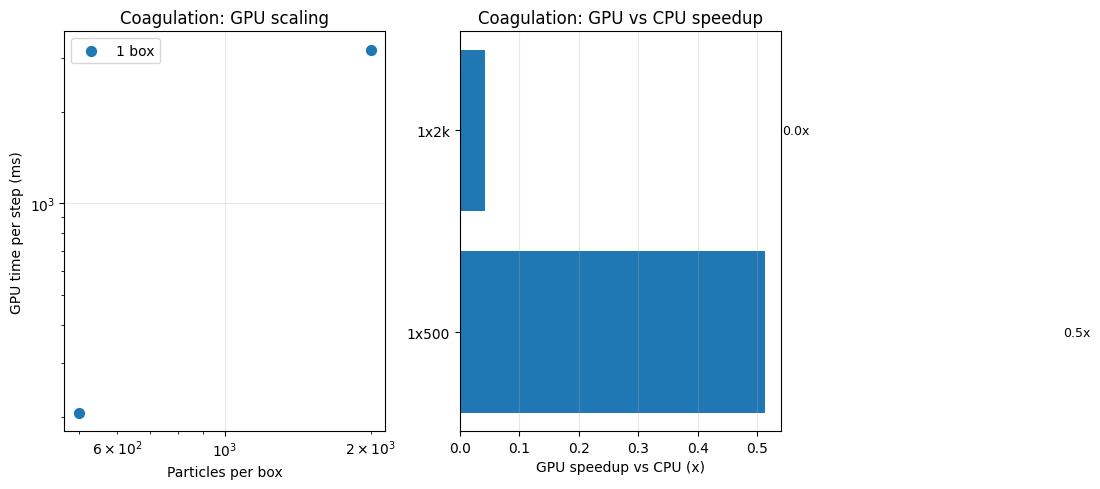

In [6]:
coag_plot_rows = [
    r for r in coag_rows if r["n_particles"] > 0 and r["gpu_per_step"] > 0
]
if not coag_plot_rows:
    print("No coagulation benchmark entries found; skipping plot.")
else:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Separate single-box vs multi-box for color coding
    single_box = [r for r in coag_plot_rows if r["n_boxes"] == 1]
    multi_box = [r for r in coag_plot_rows if r["n_boxes"] > 1]

    # Left: GPU time vs particles per box (colored by n_boxes)
    for rows, color, label in [
        (single_box, "tab:blue", "1 box"),
        (multi_box, "tab:orange", "multi-box"),
    ]:
        if rows:
            x = [r["n_particles"] for r in rows]
            y = [r["gpu_per_step"] * 1000 for r in rows]
            ax1.scatter(x, y, s=50, color=color, label=label, zorder=5)

    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel("Particles per box")
    ax1.set_ylabel("GPU time per step (ms)")
    ax1.set_title("Coagulation: GPU scaling")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Right: Speedup (where CPU data exists)
    cpu_rows = [r for r in coag_plot_rows if r["speedup"] is not None]
    if cpu_rows:
        labels = [r["label"] for r in cpu_rows]
        speedups = [r["speedup"] for r in cpu_rows]
        colors = [
            "tab:blue" if r["n_boxes"] == 1 else "tab:orange" for r in cpu_rows
        ]
        bars = ax2.barh(labels, speedups, color=colors)
        ax2.set_xlabel("GPU speedup vs CPU (x)")
        ax2.set_title("Coagulation: GPU vs CPU speedup")
        for bar, spd in zip(bars, speedups, strict=True):
            ax2.text(
                bar.get_width() + 0.5,
                bar.get_y() + bar.get_height() / 2,
                f"{spd:.1f}x",
                va="center",
                fontsize=9,
            )
        ax2.grid(True, alpha=0.3, axis="x")
    else:
        ax2.axis("off")
        ax2.set_title("Coagulation: no CPU speedup data")

    fig.tight_layout()
    plt.show()

## Interpreting results

Compare only rows with matching workloads, numerical methods, precision,
revision, and hardware context. A kernel timing is not end-to-end throughput;
explicit transfers and synchronization can change the relevant cost.

Condensation sections display data only when the loaded artifact contains
those rows. They do not establish a general speedup or recommendation.
Coagulation's one-thread-per-box path can benefit from independent-box
parallelism while large single-box workloads remain constrained.

See the [2026-07-10 coagulation decision record](../coagulation-benchmarks.md)
for its specific machine-bounded timings and caution band. Those historical
observations are not measurements of the current v0.3.0 tree or necessarily
the artifact loaded above. Current resident timing and memory qualification
remains [unavailable](../resident-benchmarks.md).